# Hafta 5 · Olasılıktan Karara: Sınıflandırma

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta05_Siniflandirma.ipynb)

**Haftanın konusu:** Sınıflandırma: lojistik regresyon, karışıklık matrisi, ROC-AUC, dengesiz veri

Bu defter, Hafta 5 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Şekil 1 (1.1):** Doğrusal olasılık modeli ile lojistik regresyon
- **Şekil 2 (1.2):** Lojistik (S) fonksiyon
- **Odds oranları (1.3)**
- **Şekil 3–5 ve tablo (2.1–2.3):** Olasılık dağılımları, iki eşikte karışıklık matrisi, dört ölçü
- **Şekil 6 ve AUC (3.1–3.2):** ROC eğrileri, AUC ve olasılık yorumu
- **Şekil 7 ve tablo (4.1–4.2):** Maliyete göre eşik seçimi
- **Şekil 8 ve tablolar (5.1–5.2):** Dengesiz veri: eşik ayarı, sınıf ağırlıkları ve olasılıkların bozulması

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 5 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta05_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## Kurulum

Hafta 2’deki kredi tablosunu büyütüyoruz. Yapay bir dünyada her başvuranın altı özelliği var: borç/gelir oranı, önceki gecikme (0/1), gelir (log), çalışma süresi, kart harcaması/gelir ve yaş. Temerrüt olasılığı bir lojistik modelle belirleniyor; **yaşın gerçek bir etkisi yok**. Model 3.000 geçmiş başvuruyla eğitiliyor, 20.000 yeni başvuruda test ediliyor.

**Hafta 4 bağlantısı:** scikit-learn’ün `LogisticRegression` sınıfı varsayılan olarak katsayılara hafif bir ceza uygular (`C` parametresi cezanın tersidir: C = 1/λ). Bu defterde `C=1e6` vererek cezayı fiilen kapatıyoruz; böylece model ekonometrideki logit modeliyle aynı olur. Defterin tamamı Colab’da yarım dakikadan kısa sürer.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

rng = np.random.default_rng(2026)   # tohum: sonuçlar ders notuyla aynı çıkar
ADLAR = ['Borç/gelir', 'Önceki gecikme', 'Gelir (log)', 'Çalışma süresi', 'Kart harcaması/gelir', 'Yaş']
BETA = np.array([0.9, 1.1, -0.6, -0.4, 0.5, 0.0])   # gerçek log-odds katsayıları; yaşın etkisi yok

def ciz(n, sabit, g=None):
    '''n başvuru üret. sabit: log-odds sabiti (temerrüt oranını belirler).'''
    g = rng if g is None else g
    X = g.normal(size=(n, 6))
    X[:, 1] = (g.random(n) < 0.15).astype(float)            # önceki gecikme: 0/1, başvuranların %15'i
    X[:, 4] = 0.4 * X[:, 0] + np.sqrt(1 - 0.16) * X[:, 4]    # kart harcaması borçla ilişkili
    X[:, 5] = 0.5 * X[:, 3] + np.sqrt(0.75) * X[:, 5]        # yaş çalışma süresiyle ilişkili
    p = 1 / (1 + np.exp(-(sabit + X @ BETA)))                # gerçek temerrüt olasılığı
    return X, (g.random(n) < p).astype(int), p

SABIT = -3.0                                    # temerrüt oranı ≈ %11
X_egt, y_egt, _ = ciz(3000, SABIT)              # eğitim: 3.000 geçmiş başvuru
X_tst, y_tst, p_tst_gercek = ciz(20000, SABIT)  # test: 20.000 yeni başvuru
print(f'Temerrüt oranı  eğitim: %{100*y_egt.mean():.1f}   test: %{100*y_tst.mean():.1f}')

Temerrüt oranı  eğitim: %10.7   test: %10.7


## 1. Neden EKK değil? (Şekil 1 ve 2)

Temerrüdü 0/1 kodlayıp EKK ile kurulan model (doğrusal olasılık modeli) olasılığı 0–1 dışına taşırabilir. Lojistik regresyon doğrusal skoru S eğrisinden geçirerek olasılığı her zaman 0 ile 1 arasında tutar.

Doğrusal olasılık modeli, test başvurularında  negatif olasılık: %16.5   1’den büyük olasılık: %0.0


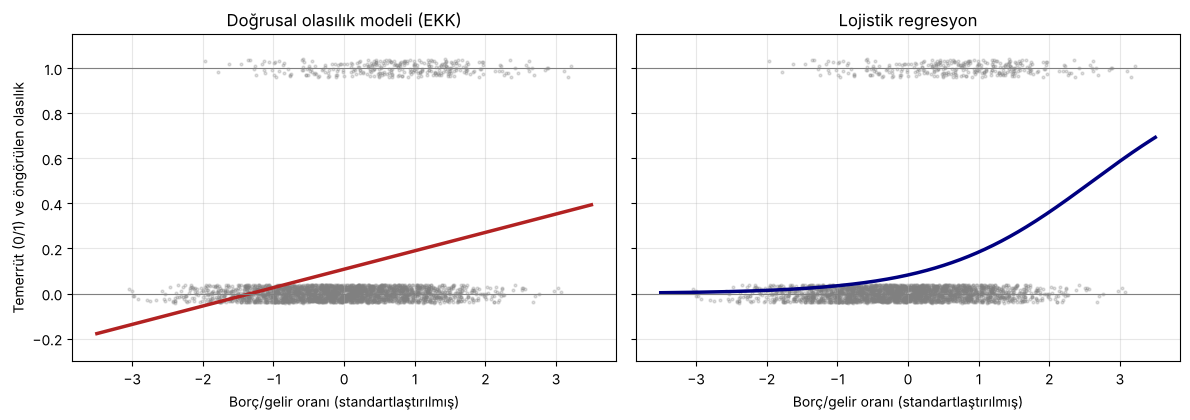

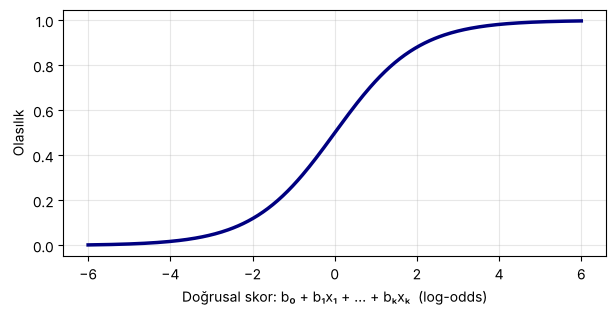

In [2]:
lpm = LinearRegression().fit(X_egt, y_egt)
p_lpm = lpm.predict(X_tst)
print(f'Doğrusal olasılık modeli, test başvurularında  negatif olasılık: %{100*(p_lpm < 0).mean():.1f}   '
      f'1’den büyük olasılık: %{100*(p_lpm > 1).mean():.1f}')

logit = LogisticRegression(C=1e6, max_iter=2000).fit(X_egt, y_egt)   # C=1e6: ceza fiilen yok
p_hat = logit.predict_proba(X_tst)[:, 1]                             # her başvuru için temerrüt olasılığı

# Şekil 1: tek değişkenle (borç/gelir) iki model
x1 = X_egt[:, [0]]; xx = np.linspace(-3.5, 3.5, 300)[:, None]
l1 = LinearRegression().fit(x1, y_egt); g1 = LogisticRegression(C=1e6).fit(x1, y_egt)
jit = np.random.default_rng(3).uniform(-0.04, 0.04, len(y_egt))     # noktaları görünür kılmak için küçük sarsıntı
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, (baslik, yy) in zip(axs, [('Doğrusal olasılık modeli (EKK)', l1.predict(xx)), ('Lojistik regresyon', g1.predict_proba(xx)[:, 1])]):
    ax.scatter(x1[:, 0], y_egt + jit, s=4, alpha=0.25, color='grey')
    ax.plot(xx, yy, lw=2.5, color='firebrick' if 'EKK' in baslik else 'navy')
    ax.axhline(0, color='grey', lw=0.8); ax.axhline(1, color='grey', lw=0.8)
    ax.set(title=baslik, xlabel='Borç/gelir oranı (standartlaştırılmış)', ylim=(-0.3, 1.15)); ax.grid(alpha=0.3)
axs[0].set_ylabel('Temerrüt (0/1) ve öngörülen olasılık'); plt.tight_layout(); plt.show()

# Şekil 2: lojistik fonksiyon
z = np.linspace(-6, 6, 300)
plt.figure(figsize=(7, 3.2)); plt.plot(z, 1 / (1 + np.exp(-z)), lw=2.5, color='navy')
plt.xlabel('Doğrusal skor: b₀ + b₁x₁ + … + bₖxₖ  (log-odds)'); plt.ylabel('Olasılık'); plt.grid(alpha=0.3); plt.show()

Beklenen: doğrusal olasılık modeli test başvurularının %16,5’ine negatif olasılık veriyor.

### Odds oranları (1.3)

Katsayının üstel değeri e^b, değişken bir birim artınca temerrüt odds’unun kaç katına çıktığını gösterir. Odds oranı olasılık oranı değildir.

In [3]:
for ad, b, gercek in zip(ADLAR, logit.coef_[0], BETA):
    print(f'{ad:22s} katsayı {b:6.3f}   odds oranı {np.exp(b):5.2f}   (gerçek katsayı {gercek:4.1f})')

Borç/gelir             katsayı  0.802   odds oranı  2.23   (gerçek katsayı  0.9)
Önceki gecikme         katsayı  0.951   odds oranı  2.59   (gerçek katsayı  1.1)
Gelir (log)            katsayı -0.594   odds oranı  0.55   (gerçek katsayı -0.6)
Çalışma süresi         katsayı -0.487   odds oranı  0.61   (gerçek katsayı -0.4)
Kart harcaması/gelir   katsayı  0.456   odds oranı  1.58   (gerçek katsayı  0.5)
Yaş                    katsayı  0.057   odds oranı  1.06   (gerçek katsayı  0.0)


Beklenen: borç/gelir 2,23, önceki gecikme 2,59, gelir 0,55. Yaşın gerçek etkisi sıfır, ama tahmin edilen odds oranı 1,06: öngörü modelinin katsayıları nedensel etki değildir.

## 2. Olasılıktan karara: eşik ve karışıklık matrisi (Şekil 3–5)

“Herkes öder” kuralının doğruluğu: %89.3

Eşik 0.5:  DP   308  YN  1826  YP   168  DN 17698
          doğruluk %90.0   duyarlılık %14.4   kesinlik %64.7   özgüllük %99.1
Eşik 0.2:  DP  1147  YN   987  YP  2122  DN 15744
          doğruluk %84.5   duyarlılık %53.7   kesinlik %35.1   özgüllük %88.1


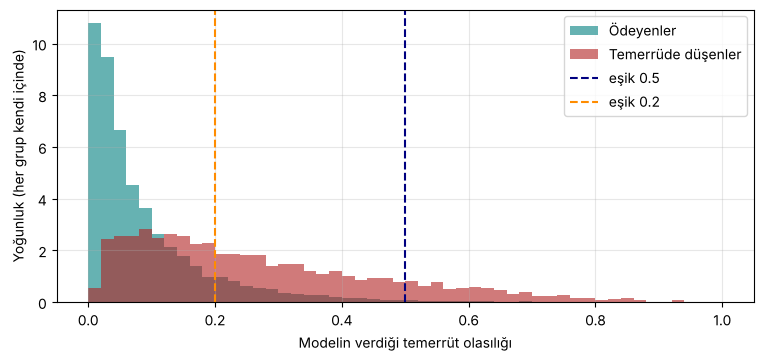

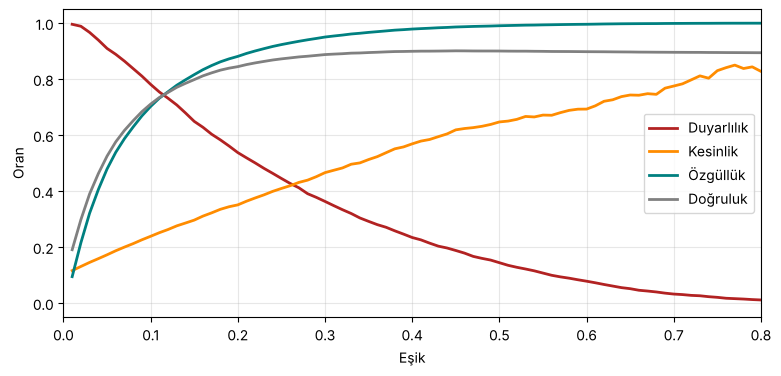

In [4]:
def olcu(y, p, esik):
    '''Eşiğin üzerindekilere “temerrüt” de; karışıklık matrisini ve dört ölçüyü döndür.'''
    yh = (p >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {'DP': tp, 'YP': fp, 'YN': fn, 'DN': tn,
            'doğruluk': (tp + tn) / len(y), 'duyarlılık': tp / (tp + fn) if tp + fn else 0.0,
            'kesinlik': tp / (tp + fp) if tp + fp else 0.0, 'özgüllük': tn / (tn + fp)}

print(f'“Herkes öder” kuralının doğruluğu: %{100*(1 - y_tst.mean()):.1f}\n')
for esik in [0.5, 0.2]:
    m = olcu(y_tst, p_hat, esik)
    print(f'Eşik {esik}:  DP {m["DP"]:5d}  YN {m["YN"]:5d}  YP {m["YP"]:5d}  DN {m["DN"]:5d}')
    print('          ' + '   '.join(f'{k} %{100*m[k]:.1f}' for k in ['doğruluk', 'duyarlılık', 'kesinlik', 'özgüllük']))

# Şekil 3: iki grubun olasılık dağılımı
plt.figure(figsize=(9, 3.8)); bins = np.linspace(0, 1, 51)
plt.hist(p_hat[y_tst == 0], bins, density=True, alpha=0.6, color='teal', label='Ödeyenler')
plt.hist(p_hat[y_tst == 1], bins, density=True, alpha=0.6, color='firebrick', label='Temerrüde düşenler')
for e, c in [(0.5, 'navy'), (0.2, 'darkorange')]: plt.axvline(e, color=c, ls='--', label=f'eşik {e}')
plt.xlabel('Modelin verdiği temerrüt olasılığı'); plt.ylabel('Yoğunluk (her grup kendi içinde)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

# Şekil 5: eşik değiştikçe dört ölçü
esikler = np.round(np.arange(0.01, 0.991, 0.01), 2)
tablo = [olcu(y_tst, p_hat, e) for e in esikler]
plt.figure(figsize=(9, 4))
for k, c in [('duyarlılık', 'firebrick'), ('kesinlik', 'darkorange'), ('özgüllük', 'teal'), ('doğruluk', 'grey')]:
    plt.plot(esikler, [t[k] for t in tablo], lw=2, color=c, label=k.capitalize())
plt.xlim(0, 0.8); plt.xlabel('Eşik'); plt.ylabel('Oran'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Beklenen: “herkes öder” %89,3. Eşik 0,5: DP 308, YN 1826, YP 168, DN 17698; doğruluk %90,0, duyarlılık %14,4. Eşik 0,2: doğruluk %84,5, duyarlılık %53,7. Eşik inince doğruluk düşüyor, yakalanan temerrüt sayısı neredeyse dört katına çıkıyor.

## 3. ROC eğrisi ve AUC (Şekil 6)

Zayıf model yalnızca gelir ve yaşı kullanıyor. AUC’nin olasılık yorumunu da kontrol ediyoruz: rastgele bir temerrüt edenle rastgele bir ödeyenden oluşan çiftlerde, model temerrüt edene ne sıklıkla daha yüksek olasılık veriyor?

AUC  tam model: 0.822   zayıf model: 0.644   gerçek olasılıklarla ulaşılabilecek en yüksek: 0.823
100.000 rastgele (temerrüt, ödeyen) çiftinde doğru sıralama payı: 0.820


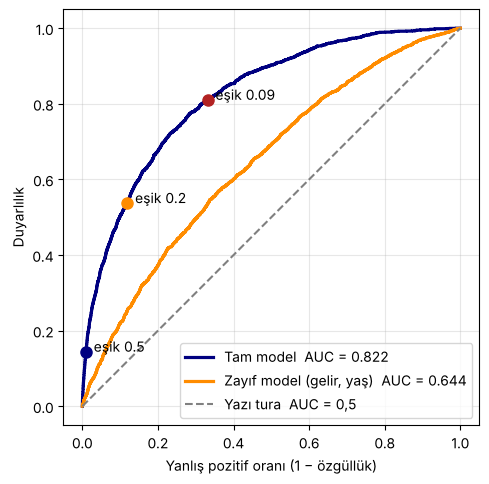

In [5]:
zayif = LogisticRegression(C=1e6, max_iter=2000).fit(X_egt[:, [2, 5]], y_egt)
p_zayif = zayif.predict_proba(X_tst[:, [2, 5]])[:, 1]
print(f'AUC  tam model: {roc_auc_score(y_tst, p_hat):.3f}   zayıf model: {roc_auc_score(y_tst, p_zayif):.3f}   '
      f'gerçek olasılıklarla ulaşılabilecek en yüksek: {roc_auc_score(y_tst, p_tst_gercek):.3f}')

g2 = np.random.default_rng(11)
i1 = g2.choice(np.where(y_tst == 1)[0], 100000); i0 = g2.choice(np.where(y_tst == 0)[0], 100000)
print(f'100.000 rastgele (temerrüt, ödeyen) çiftinde doğru sıralama payı: {(p_hat[i1] > p_hat[i0]).mean():.3f}')

plt.figure(figsize=(5.8, 5.4))
for p, ad, c in [(p_hat, 'Tam model', 'navy'), (p_zayif, 'Zayıf model (gelir, yaş)', 'darkorange')]:
    fpr, tpr, _ = roc_curve(y_tst, p); plt.plot(fpr, tpr, lw=2.3, color=c, label=f'{ad}  AUC = {roc_auc_score(y_tst, p):.3f}')
plt.plot([0, 1], [0, 1], '--', color='grey', label='Yazı tura  AUC = 0,5')
for e, c in [(0.5, 'navy'), (0.2, 'darkorange'), (0.09, 'firebrick')]:
    m = olcu(y_tst, p_hat, e); plt.plot(1 - m['özgüllük'], m['duyarlılık'], 'o', color=c, ms=8); plt.annotate(f'  eşik {e}', (1 - m['özgüllük'], m['duyarlılık']))
plt.xlabel('Yanlış pozitif oranı (1 − özgüllük)'); plt.ylabel('Duyarlılık'); plt.legend(loc='lower right'); plt.grid(alpha=0.3); plt.gca().set_aspect('equal'); plt.show()

Beklenen: AUC tam model 0,822, zayıf model 0,644, ulaşılabilecek en yüksek 0,823; çiftlerde doğru sıralama payı 0,820.

## 4. Eşiği maliyet belirler (Şekil 7)

Varsayım: temerrüde düşecek birine kredi vermek (YN) 10 birim, ödeyecek birini reddetmek (YP) 1 birim kaybettiriyor. Kuram, en iyi eşiği c_YP / (c_YP + c_YN) = 1/11 ≈ 0,09 olarak verir.

*Not:* Gösterim için eşiği test verisinde tarıyoruz. Gerçek bir uygulamada eşik, tıpkı λ gibi, eğitim verisi üzerinde (çapraz doğrulamayla) seçilmelidir.

Herkesi onayla: maliyet 1.07
Eşik 0.50: maliyet 0.92   duyarlılık %14   reddedilen iyi müşteri 168   doğruluk %90
Eşik 0.09: maliyet 0.50   duyarlılık %81   reddedilen iyi müşteri 5919   doğruluk %68
Kuramsal eşik: 0.091


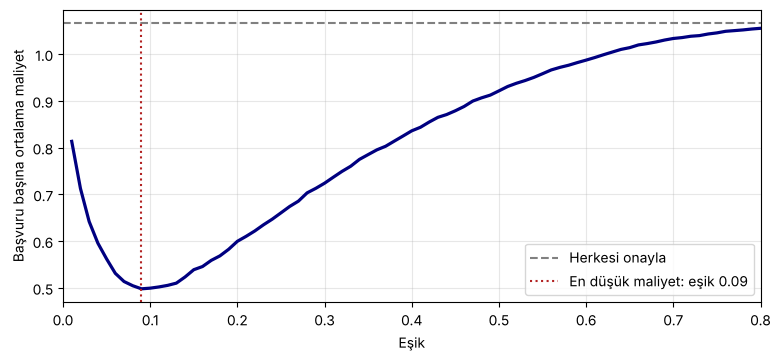

In [6]:
C_YN, C_YP = 10, 1
maliyet = np.array([(C_YN * t['YN'] + C_YP * t['YP']) / len(y_tst) for t in tablo])
en_iyi = esikler[np.argmin(maliyet)]
print(f'Herkesi onayla: maliyet {C_YN * y_tst.mean():.2f}')
for e in [0.5, en_iyi]:
    m = olcu(y_tst, p_hat, e); c = maliyet[np.where(esikler == e)[0][0]]
    print(f'Eşik {e:.2f}: maliyet {c:.2f}   duyarlılık %{100*m["duyarlılık"]:.0f}   reddedilen iyi müşteri {m["YP"]}   doğruluk %{100*m["doğruluk"]:.0f}')
print(f'Kuramsal eşik: {C_YP / (C_YP + C_YN):.3f}')

plt.figure(figsize=(9, 3.8)); plt.plot(esikler, maliyet, lw=2.3, color='navy')
plt.axhline(C_YN * y_tst.mean(), color='grey', ls='--', label='Herkesi onayla')
plt.axvline(en_iyi, color='firebrick', ls=':', label=f'En düşük maliyet: eşik {en_iyi}')
plt.xlim(0, 0.8); plt.xlabel('Eşik'); plt.ylabel('Başvuru başına ortalama maliyet'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Beklenen: herkesi onayla 1,07; eşik 0,5’te maliyet 0,92; en düşük maliyet eşik 0,09’da 0,50 (duyarlılık %81, doğruluk %68). En düşük maliyetli karar, doğruluğu en yüksek karar değildir.

## 5. Dengesiz veri (Şekil 8)

Aynı dünya, ama temerrüt oranı yaklaşık %2. Dört karar kuralını karşılaştırıyoruz: “herkes öder”, eşik 0,5, eşik 0,05 ve sınıf ağırlıklı lojistik regresyon (`class_weight='balanced'`).

Eğitim verisinde 3.000 başvurudan 63 temerrüt; test verisinde temerrüt oranı %2.2

Herkes öder                doğruluk % 97.8   duyarlılık %  0.0   kesinlik %  0.0
Lojistik, eşik 0,5         doğruluk % 97.8   duyarlılık %  3.7   kesinlik % 41.0
Lojistik, eşik 0,05        doğruluk % 89.9   duyarlılık % 48.0   kesinlik % 10.4
Sınıf ağırlıklı, eşik 0,5  doğruluk % 79.3   duyarlılık % 67.2   kesinlik %  6.8

AUC  ağırlıksız: 0.817   ağırlıklı: 0.815
Ortalama olasılık  ağırlıksız: %2.1   ağırlıklı: %28.5   (gerçek oran %2.2)


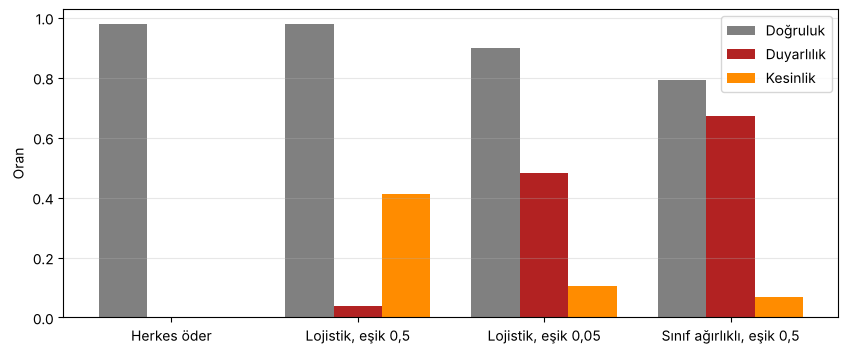

In [7]:
SABIT2 = -4.9                                  # temerrüt oranı ≈ %2
Xb_egt, yb_egt, _ = ciz(3000, SABIT2)
Xb_tst, yb_tst, _ = ciz(20000, SABIT2)
print(f'Eğitim verisinde 3.000 başvurudan {yb_egt.sum()} temerrüt; test verisinde temerrüt oranı %{100*yb_tst.mean():.1f}\n')

lb = LogisticRegression(C=1e6, max_iter=2000).fit(Xb_egt, yb_egt)
lw = LogisticRegression(C=1e6, max_iter=2000, class_weight='balanced').fit(Xb_egt, yb_egt)
pb, pw = lb.predict_proba(Xb_tst)[:, 1], lw.predict_proba(Xb_tst)[:, 1]
kurallar = {'Herkes öder': olcu(yb_tst, np.zeros(len(yb_tst)), 0.5), 'Lojistik, eşik 0,5': olcu(yb_tst, pb, 0.5),
            'Lojistik, eşik 0,05': olcu(yb_tst, pb, 0.05), 'Sınıf ağırlıklı, eşik 0,5': olcu(yb_tst, pw, 0.5)}
for ad, m in kurallar.items():
    print(f'{ad:26s} ' + '   '.join(f'{k} %{100*m[k]:5.1f}' for k in ['doğruluk', 'duyarlılık', 'kesinlik']))
print(f'\nAUC  ağırlıksız: {roc_auc_score(yb_tst, pb):.3f}   ağırlıklı: {roc_auc_score(yb_tst, pw):.3f}')
print(f'Ortalama olasılık  ağırlıksız: %{100*pb.mean():.1f}   ağırlıklı: %{100*pw.mean():.1f}   (gerçek oran %{100*yb_tst.mean():.1f})')

x = np.arange(4); w = 0.26
plt.figure(figsize=(10, 4))
for i, (k, c) in enumerate([('doğruluk', 'grey'), ('duyarlılık', 'firebrick'), ('kesinlik', 'darkorange')]):
    plt.bar(x + (i - 1) * w, [m[k] for m in kurallar.values()], w, color=c, label=k.capitalize())
plt.xticks(x, list(kurallar.keys())); plt.ylabel('Oran'); plt.legend(); plt.grid(axis='y', alpha=0.3); plt.show()

Beklenen: “herkes öder” doğruluğu %97,8; eşik 0,5’te duyarlılık %3,7; eşik 0,05’te %48,0; sınıf ağırlıklı modelde %67,2. AUC’ler neredeyse aynı (0,817 ve 0,815), ama ortalama olasılık %2,1’den %28,5’e çıkıyor: **ağırlıklandırma sıralamayı değiştirmiyor, olasılıkları bozuyor.** Olasılık fiyatlama ya da beklenen zarar için kullanılacaksa önce eşik ayarını deneyin.

Yeniden örnekleme ya da ağırlıklandırma yapılacaksa yalnızca eğitim verisine uygulanır; test verisi gerçek oranı korur (Hafta 3: önce böl, sonra hazırla).